In [1]:
from google.colab import files

uploaded = files.upload()

Saving sleep_features.csv to sleep_features.csv


In [2]:
import pandas as pd
import numpy as np
import os

features_df = pd.read_csv("sleep_features.csv")

print("Dataset loaded successfully!")
print("Shape:", features_df.shape)

display(features_df.head())

Dataset loaded successfully!
Shape: (2650, 33)


,EEG Fpz-Cz_mean,EEG Fpz-Cz_std,EEG Fpz-Cz_rms,EEG Fpz-Cz_hjorth_activity,EEG Fpz-Cz_hjorth_mobility,EEG Fpz-Cz_hjorth_complexity,EEG Fpz-Cz_delta_power,EEG Fpz-Cz_delta_relative_power,EEG Fpz-Cz_theta_power,EEG Fpz-Cz_theta_relative_power,...,EEG Pz-Oz_delta_relative_power,EEG Pz-Oz_theta_power,EEG Pz-Oz_theta_relative_power,EEG Pz-Oz_alpha_power,EEG Pz-Oz_alpha_relative_power,EEG Pz-Oz_sigma_power,EEG Pz-Oz_sigma_relative_power,EEG Pz-Oz_beta_power,EEG Pz-Oz_beta_relative_power,sleep_stage
0,7.677320e-08,0.000036,0.000036,1.299930e-09,0.200366,6.108692,6.835205e-10,0.853724,9.437714e-11,0.117878,...,0.679991,4.884113e-12,0.134649,3.253217e-12,0.089687,2.094702e-12,0.057749,2.863771e-12,0.078951,W
1,-6.469066e-07,0.000026,0.000026,6.654303e-10,0.393699,3.664441,4.029480e-10,0.810147,4.376367e-11,0.087989,...,0.401342,5.679934e-12,0.103916,7.241140e-12,0.132479,6.031485e-12,0.110348,1.528662e-11,0.279674,W
2,8.259596e-07,0.000031,0.000031,9.699986e-10,0.258863,5.597541,5.225989e-10,0.899825,2.271802e-11,0.039117,...,0.320120,5.234577e-12,0.086165,3.089535e-11,0.508558,2.902779e-12,0.047782,4.482796e-12,0.073790,W
3,-5.141783e-07,0.000018,0.000018,3.073842e-10,0.316290,4.090785,1.886731e-10,0.813741,2.051944e-11,0.088500,...,0.231959,1.280109e-11,0.152408,4.730373e-11,0.563190,1.973719e-12,0.023499,3.963850e-12,0.047193,W
4,-1.102670e-07,0.000017,0.000017,2.838617e-10,0.340875,3.508630,1.836531e-10,0.752217,4.068264e-11,0.166630,...,0.237164,2.393124e-11,0.268521,3.964185e-11,0.444802,2.576586e-12,0.028911,4.032750e-12,0.045250,W


In [3]:
print("Number of epochs:", len(features_df))

print("\nSleep-stage distribution:")
print(features_df["sleep_stage"].value_counts())

print("\nMissing values:")
print(features_df.isnull().sum().sum())

print("\nAvailable features:")
print(features_df.columns.tolist())

Number of epochs: 2650

Sleep-stage distribution:
sleep_stage
W      1997
N2      250
N3      220
REM     125
N1       58
Name: count, dtype: int64

Missing values:
0

Available features:
['EEG Fpz-Cz_mean', 'EEG Fpz-Cz_std', 'EEG Fpz-Cz_rms', 'EEG Fpz-Cz_hjorth_activity', 'EEG Fpz-Cz_hjorth_mobility', 'EEG Fpz-Cz_hjorth_complexity', 'EEG Fpz-Cz_delta_power', 'EEG Fpz-Cz_delta_relative_power', 'EEG Fpz-Cz_theta_power', 'EEG Fpz-Cz_theta_relative_power', 'EEG Fpz-Cz_alpha_power', 'EEG Fpz-Cz_alpha_relative_power', 'EEG Fpz-Cz_sigma_power', 'EEG Fpz-Cz_sigma_relative_power', 'EEG Fpz-Cz_beta_power', 'EEG Fpz-Cz_beta_relative_power', 'EEG Pz-Oz_mean', 'EEG Pz-Oz_std', 'EEG Pz-Oz_rms', 'EEG Pz-Oz_hjorth_activity', 'EEG Pz-Oz_hjorth_mobility', 'EEG Pz-Oz_hjorth_complexity', 'EEG Pz-Oz_delta_power', 'EEG Pz-Oz_delta_relative_power', 'EEG Pz-Oz_theta_power', 'EEG Pz-Oz_theta_relative_power', 'EEG Pz-Oz_alpha_power', 'EEG Pz-Oz_alpha_relative_power', 'EEG Pz-Oz_sigma_power', 'EEG Pz-Oz_sigma_r

In [4]:
PROJECT_PATH = "/content/sleepsense"

os.makedirs(PROJECT_PATH, exist_ok=True)
os.makedirs(f"{PROJECT_PATH}/data", exist_ok=True)
os.makedirs(f"{PROJECT_PATH}/processed", exist_ok=True)
os.makedirs(f"{PROJECT_PATH}/models", exist_ok=True)

features_df.to_csv(
    f"{PROJECT_PATH}/processed/sleep_features.csv",
    index=False
)

print("SleepSense workspace ready!")

SleepSense workspace ready!


In [5]:
import requests
import re
import os

DATASET_URL = "https://physionet.org/files/sleep-edfx/1.0.0/sleep-cassette/"

response = requests.get(DATASET_URL)
response.raise_for_status()

all_files = sorted(set(
    re.findall(r'href="([^"]+\.edf)"', response.text)
))

psg_files = [
    f for f in all_files if f.endswith("-PSG.edf")
]

hyp_files = [
    f for f in all_files if f.endswith("-Hypnogram.edf")
]

print("PSG recordings:", len(psg_files))
print("Hypnogram files:", len(hyp_files))

print("\nExample PSG files:")
print(psg_files[:10])

PSG recordings: 153
Hypnogram files: 153

Example PSG files:
['SC4001E0-PSG.edf', 'SC4002E0-PSG.edf', 'SC4011E0-PSG.edf', 'SC4012E0-PSG.edf', 'SC4021E0-PSG.edf', 'SC4022E0-PSG.edf', 'SC4031E0-PSG.edf', 'SC4032E0-PSG.edf', 'SC4041E0-PSG.edf', 'SC4042E0-PSG.edf']


In [6]:
#Match PSG files with hypnograms
def recording_key(filename):
    # SC4001E0-PSG.edf -> SC4001E
    return filename[:7]


def participant_id(filename):
    # SC4001E0-PSG.edf -> SC4001
    return filename[:6]


hyp_by_key = {
    recording_key(f): f
    for f in hyp_files
}

matched_recordings = []

for psg in psg_files:
    key = recording_key(psg)

    if key in hyp_by_key:
        matched_recordings.append({
            "psg": psg,
            "hypnogram": hyp_by_key[key],
            "subject": participant_id(psg)
        })

print("Matched PSG-hypnogram pairs:", len(matched_recordings))
print("\nFirst 10 matches:")

for record in matched_recordings[:10]:
    print(record)

Matched PSG-hypnogram pairs: 153

First 10 matches:
{'psg': 'SC4001E0-PSG.edf', 'hypnogram': 'SC4001EC-Hypnogram.edf', 'subject': 'SC4001'}
{'psg': 'SC4002E0-PSG.edf', 'hypnogram': 'SC4002EC-Hypnogram.edf', 'subject': 'SC4002'}
{'psg': 'SC4011E0-PSG.edf', 'hypnogram': 'SC4011EH-Hypnogram.edf', 'subject': 'SC4011'}
{'psg': 'SC4012E0-PSG.edf', 'hypnogram': 'SC4012EC-Hypnogram.edf', 'subject': 'SC4012'}
{'psg': 'SC4021E0-PSG.edf', 'hypnogram': 'SC4021EH-Hypnogram.edf', 'subject': 'SC4021'}
{'psg': 'SC4022E0-PSG.edf', 'hypnogram': 'SC4022EJ-Hypnogram.edf', 'subject': 'SC4022'}
{'psg': 'SC4031E0-PSG.edf', 'hypnogram': 'SC4031EC-Hypnogram.edf', 'subject': 'SC4031'}
{'psg': 'SC4032E0-PSG.edf', 'hypnogram': 'SC4032EP-Hypnogram.edf', 'subject': 'SC4032'}
{'psg': 'SC4041E0-PSG.edf', 'hypnogram': 'SC4041EC-Hypnogram.edf', 'subject': 'SC4041'}
{'psg': 'SC4042E0-PSG.edf', 'hypnogram': 'SC4042EC-Hypnogram.edf', 'subject': 'SC4042'}


In [7]:
#Select five new participants
first_subject = "SC4001"

selected_subjects = []
selected_recordings = []

for record in matched_recordings:

    subject = record["subject"]

    if subject == first_subject:
        continue

    if subject not in selected_subjects:
        selected_subjects.append(subject)
        selected_recordings.append(record)

    if len(selected_subjects) == 5:
        break

print("Selected participants:", selected_subjects)
print("Number of recordings:", len(selected_recordings))

for record in selected_recordings:
    print(record)

Selected participants: ['SC4002', 'SC4011', 'SC4012', 'SC4021', 'SC4022']
Number of recordings: 5
{'psg': 'SC4002E0-PSG.edf', 'hypnogram': 'SC4002EC-Hypnogram.edf', 'subject': 'SC4002'}
{'psg': 'SC4011E0-PSG.edf', 'hypnogram': 'SC4011EH-Hypnogram.edf', 'subject': 'SC4011'}
{'psg': 'SC4012E0-PSG.edf', 'hypnogram': 'SC4012EC-Hypnogram.edf', 'subject': 'SC4012'}
{'psg': 'SC4021E0-PSG.edf', 'hypnogram': 'SC4021EH-Hypnogram.edf', 'subject': 'SC4021'}
{'psg': 'SC4022E0-PSG.edf', 'hypnogram': 'SC4022EJ-Hypnogram.edf', 'subject': 'SC4022'}


In [8]:
import time

MULTI_DATA_PATH = "/content/sleepsense/multi_data"

os.makedirs(MULTI_DATA_PATH, exist_ok=True)

def download_file(filename):

    url = DATASET_URL + filename
    destination = os.path.join(MULTI_DATA_PATH, filename)

    if os.path.exists(destination):
        print("Already downloaded:", filename)
        return

    with requests.get(url, stream=True, timeout=120) as r:
        r.raise_for_status()

        with open(destination, "wb") as f:
            for chunk in r.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk)

    print("Downloaded:", filename)


for record in selected_recordings:

    download_file(record["psg"])
    download_file(record["hypnogram"])

    time.sleep(1)

print("\nAll selected recordings downloaded!")

Downloaded: SC4002E0-PSG.edf
Downloaded: SC4002EC-Hypnogram.edf
Downloaded: SC4011E0-PSG.edf
Downloaded: SC4011EH-Hypnogram.edf
Downloaded: SC4012E0-PSG.edf
Downloaded: SC4012EC-Hypnogram.edf
Downloaded: SC4021E0-PSG.edf
Downloaded: SC4021EH-Hypnogram.edf
Downloaded: SC4022E0-PSG.edf
Downloaded: SC4022EJ-Hypnogram.edf

All selected recordings downloaded!


In [9]:
downloaded_files = os.listdir(MULTI_DATA_PATH)

print("Total files:", len(downloaded_files))

for filename in sorted(downloaded_files):
    path = os.path.join(MULTI_DATA_PATH, filename)

    size_mb = os.path.getsize(path) / (1024 * 1024)

    print(f"{filename}: {size_mb:.2f} MB")

Total files: 10
SC4002E0-PSG.edf: 49.23 MB
SC4002EC-Hypnogram.edf: 0.00 MB
SC4011E0-PSG.edf: 48.74 MB
SC4011EH-Hypnogram.edf: 0.00 MB
SC4012E0-PSG.edf: 49.58 MB
SC4012EC-Hypnogram.edf: 0.00 MB
SC4021E0-PSG.edf: 48.78 MB
SC4021EH-Hypnogram.edf: 0.00 MB
SC4022E0-PSG.edf: 47.94 MB
SC4022EJ-Hypnogram.edf: 0.01 MB


# Multi-participant preprocessing

In [10]:
%pip install -q mne scipy scikit-learn joblib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.


In [11]:
import os
import mne
import numpy as np
import pandas as pd

from scipy.signal import welch

print("MNE:", mne.__version__)
print("NumPy:", np.__version__)

print("Downloaded recordings:",
      len(os.listdir(MULTI_DATA_PATH)))

MNE: 1.13.2
NumPy: 2.1.3
Downloaded recordings: 10


In [12]:
for record in selected_recordings:

    psg_path = os.path.join(
        MULTI_DATA_PATH,
        record["psg"]
    )

    raw_temp = mne.io.read_raw_edf(
        psg_path,
        preload=False,
        verbose=False
    )

    eeg_channels = [
        ch for ch in raw_temp.ch_names
        if "EEG" in ch.upper()
    ]

    print("\nParticipant:", record["subject"])
    print("Recording:", record["psg"])
    print("EEG channels:", eeg_channels)
    print("Sampling frequency:", raw_temp.info["sfreq"])

    raw_temp.close()


Participant: SC4002
Recording: SC4002E0-PSG.edf
EEG channels: ['EEG Fpz-Cz', 'EEG Pz-Oz']
Sampling frequency: 100.0

Participant: SC4011
Recording: SC4011E0-PSG.edf
EEG channels: ['EEG Fpz-Cz', 'EEG Pz-Oz']
Sampling frequency: 100.0

Participant: SC4012
Recording: SC4012E0-PSG.edf
EEG channels: ['EEG Fpz-Cz', 'EEG Pz-Oz']
Sampling frequency: 100.0

Participant: SC4021
Recording: SC4021E0-PSG.edf
EEG channels: ['EEG Fpz-Cz', 'EEG Pz-Oz']
Sampling frequency: 100.0

Participant: SC4022
Recording: SC4022E0-PSG.edf
EEG channels: ['EEG Fpz-Cz', 'EEG Pz-Oz']
Sampling frequency: 100.0


/tmp/ipykernel_1880/585692994.py:8: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw_temp = mne.io.read_raw_edf(
/tmp/ipykernel_1880/585692994.py:8: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw_temp = mne.io.read_raw_edf(
/tmp/ipykernel_1880/585692994.py:8: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw_temp = mne.io.read_raw_edf(
/tmp/ipykernel_1880/585692994.py:8: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw_temp = mne.io.read_raw_edf(
/tmp/ipykernel_1880/585692994.py:8: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw_temp = mne.io.read_raw_edf(
/tmp/ipykernel_1880/585692994.py:8: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7,

In [13]:
#Define the common feature extraction functions
def extract_time_features(signal):

    signal = np.asarray(signal)

    activity = np.var(signal)

    first_derivative = np.diff(signal)
    second_derivative = np.diff(first_derivative)

    mobility = (
        np.sqrt(np.var(first_derivative) / activity)
        if activity > 0 else 0
    )

    complexity = (
        np.sqrt(
            np.var(second_derivative) /
            np.var(first_derivative)
        ) / mobility
        if np.var(first_derivative) > 0 and mobility > 0
        else 0
    )

    return {
        "mean": np.mean(signal),
        "std": np.std(signal),
        "rms": np.sqrt(np.mean(signal ** 2)),
        "hjorth_activity": activity,
        "hjorth_mobility": mobility,
        "hjorth_complexity": complexity
    }


def extract_frequency_features(signal, sfreq):

    frequencies, psd = welch(
        signal,
        fs=sfreq,
        nperseg=min(len(signal), int(4 * sfreq))
    )

    bands = {
        "delta": (0.5, 4),
        "theta": (4, 8),
        "alpha": (8, 13),
        "sigma": (11, 16),
        "beta": (13, 30)
    }

    total_mask = (
        (frequencies >= 0.5) &
        (frequencies <= 35)
    )

    total_power = np.trapezoid(
        psd[total_mask],
        frequencies[total_mask]
    )

    features = {}

    for band, (low, high) in bands.items():

        mask = (
            (frequencies >= low) &
            (frequencies <= high)
        )

        power = (
            np.trapezoid(psd[mask], frequencies[mask])
            if np.sum(mask) >= 2 else 0
        )

        features[f"{band}_power"] = power

        features[f"{band}_relative_power"] = (
            power / total_power
            if total_power > 0 else 0
        )

    return features

In [14]:
for record in selected_recordings:

    hyp_path = os.path.join(
        MULTI_DATA_PATH,
        record["hypnogram"]
    )

    annotations = mne.read_annotations(hyp_path)

    print("\nParticipant:", record["subject"])
    print(pd.Series(
        annotations.description
    ).value_counts().to_dict())


Participant: SC4002
{'Sleep stage 2': 37, 'Sleep stage 1': 32, 'Sleep stage 3': 30, 'Sleep stage W': 23, 'Sleep stage 4': 16, 'Sleep stage R': 12, 'Movement time': 1, 'Sleep stage ?': 1}

Participant: SC4011
{'Sleep stage 2': 40, 'Sleep stage 1': 33, 'Sleep stage 3': 21, 'Sleep stage W': 15, 'Sleep stage 4': 8, 'Sleep stage R': 8, 'Sleep stage ?': 1}

Participant: SC4012
{'Sleep stage 2': 55, 'Sleep stage 1': 42, 'Sleep stage 3': 29, 'Sleep stage R': 18, 'Sleep stage W': 17, 'Sleep stage 4': 9, 'Sleep stage ?': 1}

Participant: SC4021
{'Sleep stage 2': 56, 'Sleep stage 3': 43, 'Sleep stage 1': 22, 'Sleep stage R': 15, 'Sleep stage 4': 15, 'Sleep stage W': 9, 'Sleep stage ?': 1}

Participant: SC4022
{'Sleep stage 2': 63, 'Sleep stage 1': 52, 'Sleep stage 3': 34, 'Sleep stage 4': 11, 'Sleep stage R': 11, 'Sleep stage W': 6, 'Movement time': 1, 'Sleep stage ?': 1}


In [15]:
#2nd EEG channel consistency
channel_summary = {}

for record in selected_recordings:

    psg_path = os.path.join(
        MULTI_DATA_PATH,
        record["psg"]
    )

    raw_temp = mne.io.read_raw_edf(
        psg_path,
        preload=False,
        verbose=False
    )

    eeg_channels = [
        ch for ch in raw_temp.ch_names
        if "EEG" in ch.upper()
    ]

    channel_summary[record["subject"]] = eeg_channels

    print(
        record["subject"],
        ":", eeg_channels
    )

    raw_temp.close()

SC4002 : ['EEG Fpz-Cz', 'EEG Pz-Oz']
SC4011 : ['EEG Fpz-Cz', 'EEG Pz-Oz']
SC4012 : ['EEG Fpz-Cz', 'EEG Pz-Oz']
SC4021 : ['EEG Fpz-Cz', 'EEG Pz-Oz']
SC4022 : ['EEG Fpz-Cz', 'EEG Pz-Oz']


/tmp/ipykernel_1880/3070908076.py:11: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw_temp = mne.io.read_raw_edf(
/tmp/ipykernel_1880/3070908076.py:11: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw_temp = mne.io.read_raw_edf(
/tmp/ipykernel_1880/3070908076.py:11: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw_temp = mne.io.read_raw_edf(
/tmp/ipykernel_1880/3070908076.py:11: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw_temp = mne.io.read_raw_edf(
/tmp/ipykernel_1880/3070908076.py:11: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw_temp = mne.io.read_raw_edf(
/tmp/ipykernel_1880/3070908076.py:11: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff fr

In [16]:
unique_channel_sets = {
    tuple(channels)
    for channels in channel_summary.values()
}

print("Different channel configurations:",
      len(unique_channel_sets))

print("Channel configurations:",
      unique_channel_sets)

Different channel configurations: 1
Channel configurations: {('EEG Fpz-Cz', 'EEG Pz-Oz')}


# Set up multi-subject preprocessing

In [17]:
import os
import mne
import numpy as np
import pandas as pd
from scipy.signal import welch
from collections import Counter

MULTI_DATA_PATH = "/content/sleepsense/multi_data"

stage_mapping = {
    "Sleep stage W": "W",
    "Sleep stage 1": "N1",
    "Sleep stage 2": "N2",
    "Sleep stage 3": "N3",
    "Sleep stage 4": "N3",
    "Sleep stage R": "REM"
}

common_eeg_channels = [
    "EEG Fpz-Cz",
    "EEG Pz-Oz"
]

print("Channels:", common_eeg_channels)
print("Stage mapping:", stage_mapping)

Channels: ['EEG Fpz-Cz', 'EEG Pz-Oz']
Stage mapping: {'Sleep stage W': 'W', 'Sleep stage 1': 'N1', 'Sleep stage 2': 'N2', 'Sleep stage 3': 'N3', 'Sleep stage 4': 'N3', 'Sleep stage R': 'REM'}


In [18]:
#Feature extraction functions
def extract_time_features(signal, sfreq):
    features = {}

    mean_val = np.mean(signal)
    std_val = np.std(signal)
    rms = np.sqrt(np.mean(signal ** 2))

    diff1 = np.diff(signal)
    diff2 = np.diff(diff1)

    activity = np.var(signal)
    mobility = (
        np.sqrt(np.var(diff1) / activity)
        if activity > 0 else 0
    )

    complexity = (
        np.sqrt(np.var(diff2) / np.var(diff1)) / mobility
        if np.var(diff1) > 0 and mobility > 0 else 0
    )

    features["mean"] = mean_val
    features["std"] = std_val
    features["rms"] = rms
    features["hjorth_activity"] = activity
    features["hjorth_mobility"] = mobility
    features["hjorth_complexity"] = complexity

    return features


def extract_frequency_features(signal, sfreq):
    frequencies, psd = welch(
        signal,
        fs=sfreq,
        nperseg=min(len(signal), int(sfreq * 4))
    )

    bands = {
        "delta": (0.5, 4),
        "theta": (4, 8),
        "alpha": (8, 13),
        "sigma": (11, 16),
        "beta": (13, 30)
    }

    features = {}
    total_power = np.trapezoid(psd, frequencies)

    for band, (low, high) in bands.items():
        mask = (frequencies >= low) & (frequencies <= high)

        power = (
            np.trapezoid(psd[mask], frequencies[mask])
            if np.sum(mask) >= 2 else 0
        )

        features[f"{band}_power"] = power
        features[f"{band}_relative_power"] = (
            power / total_power if total_power > 0 else 0
        )

    return features


def extract_epoch_features(epoch, channel_names, sfreq):
    features = {}

    for channel_idx, channel_name in enumerate(channel_names):
        signal = epoch[channel_idx]

        time_features = extract_time_features(signal, sfreq)
        frequency_features = extract_frequency_features(signal, sfreq)

        for name, value in time_features.items():
            features[f"{channel_name}_{name}"] = value

        for name, value in frequency_features.items():
            features[f"{channel_name}_{name}"] = value

    return features

# Process all five recordings

In [19]:
#Automated preprocessing and feature extraction
def process_recording(record):

    subject_id = record["subject"]
    psg_path = os.path.join(MULTI_DATA_PATH, record["psg"])
    hyp_path = os.path.join(MULTI_DATA_PATH, record["hypnogram"])

    print(f"\nProcessing {subject_id}...")

    raw = mne.io.read_raw_edf(
        psg_path,
        preload=True,
        verbose=False
    )

    annotations = mne.read_annotations(hyp_path)
    raw.set_annotations(annotations)

    missing_channels = [
        ch for ch in common_eeg_channels
        if ch not in raw.ch_names
    ]

    if missing_channels:
        raise ValueError(
            f"{subject_id}: Missing channels {missing_channels}"
        )

    eeg_raw = raw.copy().pick(common_eeg_channels)

    sfreq = eeg_raw.info["sfreq"]

    if sfreq <= 70:
        raise ValueError(
            f"{subject_id}: Sampling frequency {sfreq} "
            "is too low for a 35 Hz high-pass boundary."
        )

    eeg_raw.filter(
        l_freq=0.3,
        h_freq=35.0,
        method="fir",
        verbose=False
    )

    events, event_id = mne.events_from_annotations(
        eeg_raw,
        event_id={
            annotation: index + 1
            for index, annotation in enumerate(stage_mapping)
        },
        chunk_duration=30.0,
        verbose=False
    )

    epochs = mne.Epochs(
        eeg_raw,
        events,
        event_id=event_id,
        tmin=0,
        tmax=30 - 1 / sfreq,
        baseline=None,
        preload=True,
        reject_by_annotation=True,
        verbose=False
    )

    rows = []

    for epoch_index, (epoch, event) in enumerate(
        zip(epochs.get_data(), epochs.events)
    ):

        annotation_name = next(
            name for name, code in event_id.items()
            if code == event[2]
        )

        stage = stage_mapping[annotation_name]

        row = extract_epoch_features(
            epoch,
            common_eeg_channels,
            sfreq
        )

        row["sleep_stage"] = stage
        row["subject_id"] = subject_id
        row["recording_id"] = record["psg"].replace("-PSG.edf", "")
        row["epoch_index"] = epoch_index

        rows.append(row)

    result = pd.DataFrame(rows)

    print("Sampling frequency:", sfreq)
    print("Processed epochs:", len(result))
    print("Stage distribution:", result["sleep_stage"].value_counts().to_dict())

    raw.close()

    return result

In [20]:
#Process the five participants
all_subject_features = []

for record in selected_recordings:

    subject_df = process_recording(record)

    all_subject_features.append(subject_df)

new_features_df = pd.concat(
    all_subject_features,
    ignore_index=True
)

print("\nAll five participants processed.")
print("Total epochs:", len(new_features_df))
print("Participants:", new_features_df["subject_id"].nunique())

display(new_features_df.head())


Processing SC4002...


/tmp/ipykernel_1880/1512893131.py:10: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
/tmp/ipykernel_1880/1512893131.py:10: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
/tmp/ipykernel_1880/1512893131.py:10: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
/tmp/ipykernel_1880/1512893131.py:17: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)


Sampling frequency: 100.0
Processed epochs: 2829
Stage distribution: {'W': 1885, 'N2': 373, 'N3': 297, 'REM': 215, 'N1': 59}

Processing SC4011...


/tmp/ipykernel_1880/1512893131.py:10: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
/tmp/ipykernel_1880/1512893131.py:10: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
/tmp/ipykernel_1880/1512893131.py:10: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
/tmp/ipykernel_1880/1512893131.py:17: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)


Sampling frequency: 100.0
Processed epochs: 2802
Stage distribution: {'W': 1856, 'N2': 562, 'REM': 170, 'N1': 109, 'N3': 105}

Processing SC4012...


...

/tmp/ipykernel_1880/1512893131.py:10: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
/tmp/ipykernel_1880/1512893131.py:10: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
/tmp/ipykernel_1880/1512893131.py:10: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
/tmp/ipykernel_1880/1512893131.py:17: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)


Sampling frequency: 100.0
Processed epochs: 2804
Stage distribution: {'W': 1907, 'N2': 545, 'REM': 163, 'N3': 95, 'N1': 94}

Processing SC4022...


/tmp/ipykernel_1880/1512893131.py:10: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
/tmp/ipykernel_1880/1512893131.py:10: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(
/tmp/ipykernel_1880/1512893131.py:10: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(
/tmp/ipykernel_1880/1512893131.py:17: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw.set_annotations(annotations)


Sampling frequency: 100.0
Processed epochs: 2755
Stage distribution: {'W': 1871, 'N2': 402, 'N1': 184, 'REM': 179, 'N3': 119}

All five participants processed.
Total epochs: 14038
Participants: 5


,EEG Fpz-Cz_mean,EEG Fpz-Cz_std,EEG Fpz-Cz_rms,EEG Fpz-Cz_hjorth_activity,EEG Fpz-Cz_hjorth_mobility,EEG Fpz-Cz_hjorth_complexity,EEG Fpz-Cz_delta_power,EEG Fpz-Cz_delta_relative_power,EEG Fpz-Cz_theta_power,EEG Fpz-Cz_theta_relative_power,...,EEG Pz-Oz_alpha_power,EEG Pz-Oz_alpha_relative_power,EEG Pz-Oz_sigma_power,EEG Pz-Oz_sigma_relative_power,EEG Pz-Oz_beta_power,EEG Pz-Oz_beta_relative_power,sleep_stage,subject_id,recording_id,epoch_index
0,1.240758e-06,0.000031,0.000031,9.611572e-10,0.379060,3.861822,5.586250e-10,0.541656,7.319650e-11,0.070973,...,4.323261e-12,0.104291,2.024188e-12,0.048830,3.190523e-12,0.076966,W,SC4002,SC4002E0,0
1,2.148764e-07,0.000040,0.000040,1.637222e-09,0.260870,5.554228,7.560830e-10,0.440761,3.933936e-11,0.022933,...,4.447290e-11,0.138795,3.807001e-12,0.011881,5.106366e-12,0.015936,W,SC4002,SC4002E0,1
2,7.864648e-07,0.000031,0.000031,9.594765e-10,0.283529,4.392105,4.899001e-10,0.499513,1.031399e-10,0.105164,...,3.874929e-11,0.062880,3.652368e-12,0.005927,5.033725e-12,0.008168,W,SC4002,SC4002E0,2
3,-9.486553e-07,0.000048,0.000048,2.289322e-09,0.336134,4.345209,1.242530e-09,0.503659,1.339787e-10,0.054308,...,8.486916e-12,0.016419,4.060160e-12,0.007855,5.847313e-12,0.011313,W,SC4002,SC4002E0,3
4,5.435320e-08,0.000037,0.000037,1.357188e-09,0.387838,3.715880,8.434211e-10,0.619528,1.255837e-10,0.092247,...,6.828305e-12,0.097683,4.866219e-12,0.069614,8.720105e-12,0.124746,W,SC4002,SC4002E0,4


# Combine with your existing SC4001 data

In [21]:
#Merge datasets
baseline_df = pd.read_csv(
    "/content/sleepsense/processed/sleep_features.csv"
)

baseline_df["subject_id"] = "SC4001"
baseline_df["recording_id"] = "SC4001E0"
baseline_df["epoch_index"] = np.arange(len(baseline_df))

metadata_columns = [
    "sleep_stage",
    "subject_id",
    "recording_id",
    "epoch_index"
]

baseline_feature_columns = [
    col for col in baseline_df.columns
    if col not in metadata_columns
]

new_feature_columns = [
    col for col in new_features_df.columns
    if col not in metadata_columns
]

if set(baseline_feature_columns) != set(new_feature_columns):
    print("Feature columns do not match.")
    print("Missing from new data:",
          set(baseline_feature_columns) - set(new_feature_columns))
    print("Extra in new data:",
          set(new_feature_columns) - set(baseline_feature_columns))
    raise ValueError("Resolve feature mismatch before merging.")

new_features_df = new_features_df[
    baseline_feature_columns + metadata_columns
]

baseline_df = baseline_df[
    baseline_feature_columns + metadata_columns
]

combined_df = pd.concat(
    [baseline_df, new_features_df],
    ignore_index=True
)

print("Total epochs:", len(combined_df))
print("Total participants:", combined_df["subject_id"].nunique())

display(combined_df.head())

Total epochs: 16688
Total participants: 6


,EEG Fpz-Cz_mean,EEG Fpz-Cz_std,EEG Fpz-Cz_rms,EEG Fpz-Cz_hjorth_activity,EEG Fpz-Cz_hjorth_mobility,EEG Fpz-Cz_hjorth_complexity,EEG Fpz-Cz_delta_power,EEG Fpz-Cz_delta_relative_power,EEG Fpz-Cz_theta_power,EEG Fpz-Cz_theta_relative_power,...,EEG Pz-Oz_alpha_power,EEG Pz-Oz_alpha_relative_power,EEG Pz-Oz_sigma_power,EEG Pz-Oz_sigma_relative_power,EEG Pz-Oz_beta_power,EEG Pz-Oz_beta_relative_power,sleep_stage,subject_id,recording_id,epoch_index
0,7.677320e-08,0.000036,0.000036,1.299930e-09,0.200366,6.108692,6.835205e-10,0.853724,9.437714e-11,0.117878,...,3.253217e-12,0.089687,2.094702e-12,0.057749,2.863771e-12,0.078951,W,SC4001,SC4001E0,0
1,-6.469066e-07,0.000026,0.000026,6.654303e-10,0.393699,3.664441,4.029480e-10,0.810147,4.376367e-11,0.087989,...,7.241140e-12,0.132479,6.031485e-12,0.110348,1.528662e-11,0.279674,W,SC4001,SC4001E0,1
2,8.259596e-07,0.000031,0.000031,9.699986e-10,0.258863,5.597541,5.225989e-10,0.899825,2.271802e-11,0.039117,...,3.089535e-11,0.508558,2.902779e-12,0.047782,4.482796e-12,0.073790,W,SC4001,SC4001E0,2
3,-5.141783e-07,0.000018,0.000018,3.073842e-10,0.316290,4.090785,1.886731e-10,0.813741,2.051944e-11,0.088500,...,4.730373e-11,0.563190,1.973719e-12,0.023499,3.963850e-12,0.047193,W,SC4001,SC4001E0,3
4,-1.102670e-07,0.000017,0.000017,2.838617e-10,0.340875,3.508630,1.836531e-10,0.752217,4.068264e-11,0.166630,...,3.964185e-11,0.444802,2.576586e-12,0.028911,4.032750e-12,0.045250,W,SC4001,SC4001E0,4


In [22]:
 output_path = (
    "/content/sleepsense/processed/multi_subject_features.csv"
)

os.makedirs(os.path.dirname(output_path), exist_ok=True)

combined_df.to_csv(output_path, index=False)

print("Saved:", output_path)

from google.colab import files
files.download(output_path)

Saved: /content/sleepsense/processed/multi_subject_features.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
#Final dataset validation
print("DATASET VALIDATION")
print("-" * 45)

print("Dataset shape:", combined_df.shape)

print("\nParticipants:")
print(sorted(combined_df["subject_id"].unique()))

print("\nSleep stages:")
print(sorted(combined_df["sleep_stage"].unique()))

print("\nMissing values:")
print(combined_df.isnull().sum().sum())

print("\nDuplicate rows:")
print(combined_df.duplicated().sum())

print("\nParticipant-wise epoch counts:")
print(combined_df.groupby("subject_id").size())

print("\nClass distribution:")
print(combined_df["sleep_stage"].value_counts())

DATASET VALIDATION
---------------------------------------------
Dataset shape: (16688, 36)

Participants:
['SC4001', 'SC4002', 'SC4011', 'SC4012', 'SC4021', 'SC4022']

Sleep stages:
['N1', 'N2', 'N3', 'REM', 'W']

Missing values:
0

Duplicate rows:
0

Participant-wise epoch counts:
subject_id
SC4001    2650
SC4002    2829
SC4011    2802
SC4012    2848
SC4021    2804
SC4022    2755
dtype: int64

Class distribution:
sleep_stage
W      11340
N2      2792
REM     1028
N3       932
N1       596
Name: count, dtype: int64


# Train and evaluate the multi-subject Random Forest

In [24]:
#Prepare the data
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    cohen_kappa_score
)

import numpy as np
import pandas as pd

# Metadata columns must not be used as model features
metadata_columns = [
    "sleep_stage",
    "subject_id",
    "recording_id",
    "epoch_index"
]

feature_columns = [
    col for col in combined_df.columns
    if col not in metadata_columns
]

X = combined_df[feature_columns].astype(float)
y = combined_df["sleep_stage"]
groups = combined_df["subject_id"]

stage_order = ["W", "N1", "N2", "N3", "REM"]

print("Feature count:", len(feature_columns))
print("Total samples:", len(X))
print("Participants:", groups.nunique())

Feature count: 32
Total samples: 16688
Participants: 6


In [25]:
#Run Leave-One-Subject-Out cross-validation
logo = LeaveOneGroupOut()

oof_predictions = np.empty(len(y), dtype=object)
fold_results = []

for fold, (train_idx, test_idx) in enumerate(
    logo.split(X, y, groups),
    start=1
):

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    test_subject = groups.iloc[test_idx].iloc[0]

    model = RandomForestClassifier(
        n_estimators=300,
        max_depth=15,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    oof_predictions[test_idx] = predictions

    fold_results.append({
        "subject_id": test_subject,
        "test_epochs": len(test_idx),
        "accuracy": accuracy_score(y_test, predictions),
        "balanced_accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "macro_f1": f1_score(
            y_test, predictions, average="macro",
            labels=stage_order, zero_division=0
        ),
        "cohen_kappa": cohen_kappa_score(
            y_test, predictions
        )
    })

    print(
        f"Fold {fold}/6 | "
        f"Held-out participant: {test_subject} | "
        f"Macro F1: {fold_results[-1]['macro_f1']:.4f}"
    )

fold_results_df = pd.DataFrame(fold_results)

print("\nSubject-wise evaluation:")
display(fold_results_df)

Fold 1/6 | Held-out participant: SC4001 | Macro F1: 0.6946
Fold 2/6 | Held-out participant: SC4002 | Macro F1: 0.5899
Fold 3/6 | Held-out participant: SC4011 | Macro F1: 0.8441
Fold 4/6 | Held-out participant: SC4012 | Macro F1: 0.7892
Fold 5/6 | Held-out participant: SC4021 | Macro F1: 0.7752
Fold 6/6 | Held-out participant: SC4022 | Macro F1: 0.6501

Subject-wise evaluation:


,subject_id,test_epochs,accuracy,balanced_accuracy,macro_f1,cohen_kappa
0,SC4001,2650,0.937358,0.731477,0.694601,0.852412
1,SC4002,2829,0.882291,0.629870,0.589857,0.774065
2,SC4011,2802,0.943612,0.844437,0.844067,0.890127
3,SC4012,2848,0.938202,0.794992,0.789180,0.883774
4,SC4021,2804,0.931170,0.755359,0.775187,0.858933
5,SC4022,2755,0.880581,0.670846,0.650125,0.763504


In [26]:
overall_accuracy = accuracy_score(y, oof_predictions)

overall_balanced_accuracy = balanced_accuracy_score(
    y, oof_predictions
)

overall_macro_f1 = f1_score(
    y,
    oof_predictions,
    average="macro",
    labels=stage_order,
    zero_division=0
)

overall_kappa = cohen_kappa_score(y, oof_predictions)

print("OVERALL LOSO PERFORMANCE")
print("-" * 40)

print(f"Accuracy:          {overall_accuracy:.4f}")
print(f"Balanced Accuracy: {overall_balanced_accuracy:.4f}")
print(f"Macro F1:          {overall_macro_f1:.4f}")
print(f"Cohen's Kappa:     {overall_kappa:.4f}")

OVERALL LOSO PERFORMANCE
----------------------------------------
Accuracy:          0.9188
Balanced Accuracy: 0.7382
Macro F1:          0.7473
Cohen's Kappa:     0.8380


In [27]:
#Per-stage classification report
print(
    classification_report(
        y,
        oof_predictions,
        labels=stage_order,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           W       0.99      0.98      0.98     11340
          N1       0.41      0.29      0.34       596
          N2       0.82      0.92      0.87      2792
          N3       0.89      0.84      0.86       932
         REM       0.71      0.67      0.69      1028

    accuracy                           0.92     16688
   macro avg       0.76      0.74      0.75     16688
weighted avg       0.91      0.92      0.92     16688



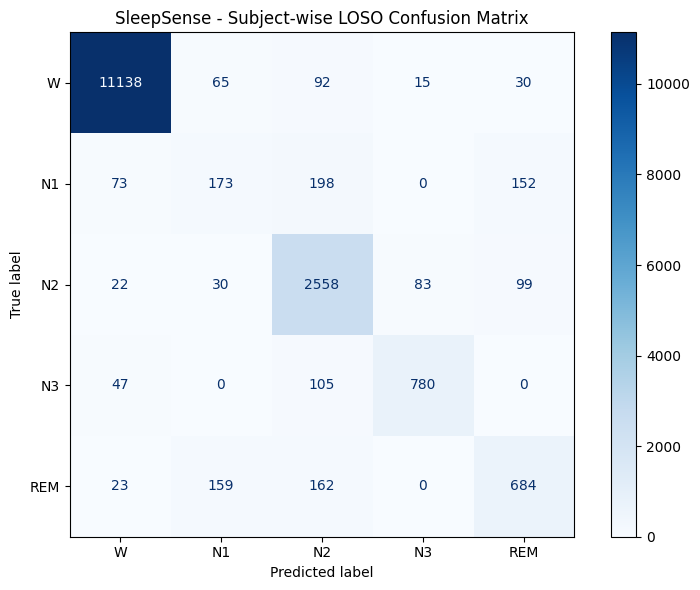

In [28]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    y,
    oof_predictions,
    labels=stage_order
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=stage_order
)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("SleepSense - Subject-wise LOSO Confusion Matrix")
plt.tight_layout()
plt.show()

In [29]:
results_df = combined_df[
    ["subject_id", "recording_id", "sleep_stage"]
].copy()

results_df["predicted_stage"] = oof_predictions

results_path = (
    "/content/sleepsense/processed/loso_predictions.csv"
)

results_df.to_csv(results_path, index=False)

fold_results_df.to_csv(
    "/content/sleepsense/processed/loso_fold_metrics.csv",
    index=False
)

print("Evaluation files saved.")

Evaluation files saved.
